# LSTM/GRU и текстовые представления. Генерация музыки

**Мотыгуллин Булат Габдулхакович**  
**Группа: Б01-301г**  
**Вариант: 11**

In [1]:
from course import *

seed_all(11)
OUT = ROOT / "results" / "10_music_generation"
OUT.mkdir(exist_ok=True, parents=True)

## Общая часть. Текст, padding, embedding, RNN/LSTM/GRU

На синтетических текстах сравниваю RNN, LSTM и GRU. Словарь строю по train, PAD исключаю при обработке последовательностей. На том же корпусе обучаю Word2Vec и FastText, проверяю неизвестные слова.

Данные синтетические: настроение определяется выбранным словом. PAD=0, UNK=1, max_length=20.
the story was awful and the movie felt awful yesterday [2, 3, 4, 18, 6, 2, 7, 8, 18, 14, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Word tokens: ['the', 'story', 'was', 'awful', 'and', 'the', 'movie', 'felt', 'awful', 'yesterday'] char tokens: ['t', 'h', 'e', ' ', 's', 't', 'o', 'r', 'y', ' ', 'w', 'a', 's', ' ', 'a', 'w', 'f', 'u', 'l', ' ']


,architecture,accuracy,macro_f1,seconds
0,RNN,1.0,1.0,0.10778
1,LSTM,1.0,1.0,0.13827
2,GRU,1.0,1.0,0.11662


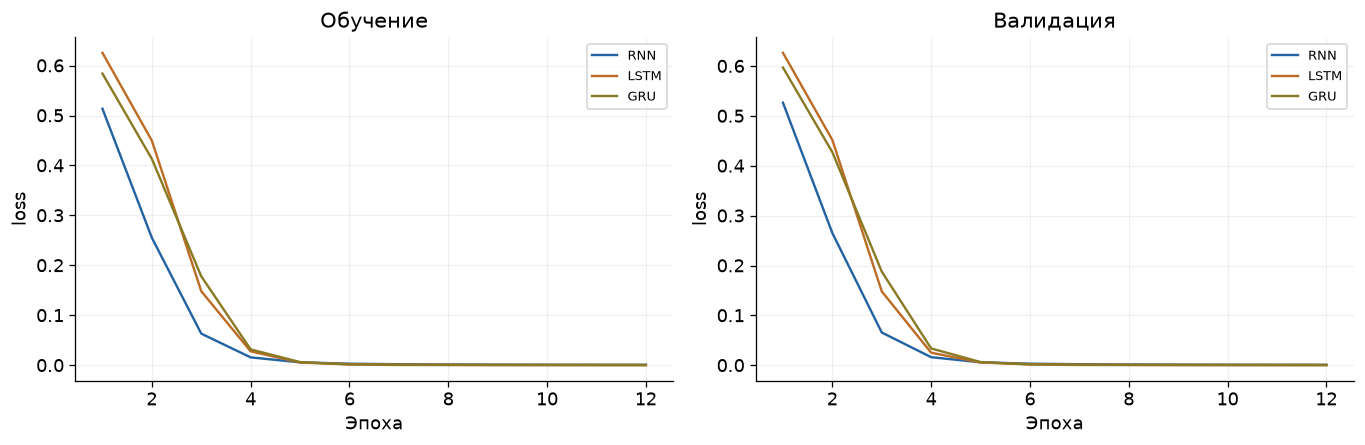

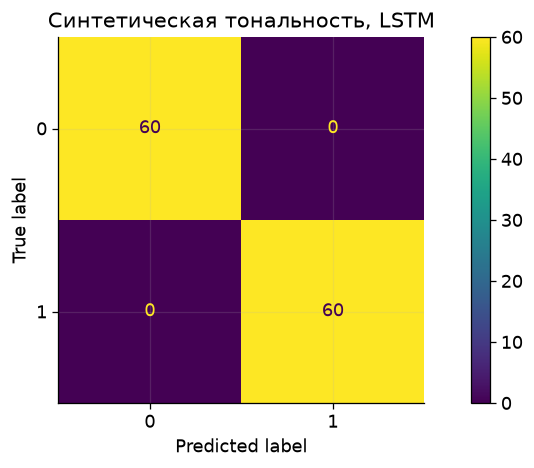

,text,truth,prediction,length
0,the story was great and the movie felt great t...,1,1,10
1,the movie was awful and the movie felt awful t...,0,0,10
2,the music was great and the movie felt great y...,1,1,10
3,the music was dull and the movie felt dull today,0,0,10
4,the movie was great and the movie felt great t...,1,1,10
5,the dialogue was boring and the movie felt bor...,0,0,10
6,the dialogue was wonderful and the movie felt ...,1,1,10
7,the story was great and the movie felt great t...,1,1,10
8,the story was brilliant and the movie felt bri...,1,1,10
9,the acting was awful and the movie felt awful ...,0,0,10


Test: {'accuracy': 1.0, 'macro_f1': 1.0}


,class,precision,recall,f1-score,support
0,0,1.0,1.0,1.0,60.0
1,1,1.0,1.0,1.0,60.0
2,accuracy,1.0,1.0,1.0,1.0
3,macro avg,1.0,1.0,1.0,120.0
4,weighted avg,1.0,1.0,1.0,120.0


В этом синтетическом корпусе класс задан ключевым словом. Высокая точность здесь показывает работу модели на простой задаче.

,model,word,neighbors
0,Word2Vec,movie,"[('music', 0.9551280736923218), ('dialogue', 0..."
1,FastText,movie,"[('music', 0.9955661296844482), ('acting', 0.9..."
2,Word2Vec,excellent,"[('boring', 0.9111047983169556), ('the', 0.908..."
3,FastText,excellent,"[('brilliant', 0.9971699714660645), ('ending',..."
4,Word2Vec,boring,"[('music', 0.930778443813324), ('terrible', 0...."
5,FastText,boring,"[('ending', 0.9969813227653503), ('story', 0.9..."


Cosine movie/story: 0.9426692
OOV excellentness in Word2Vec: False FastText vector norm: 0.6273414


,query,expected_relation,answer,top3,semantic_check
0,great+awful−excellent,negative adjective,acting,"[('acting', 0.7602710127830505), ('ending', 0....",нелогичный перенос отношения
1,story+excellent−movie,positive adjective,boring,"[('boring', 0.9170696139335632), ('music', 0.8...",нелогичный перенос отношения
2,music+boring−movie,negative adjective,terrible,"[('terrible', 0.9271185994148254), ('story', 0...",согласуется с ожидаемой группой


Аналогии проверяю по заданным группам слов. На маленьком корпусе ближайшие соседи могут отражать сходный контекст без сохранения смысла аналогии.

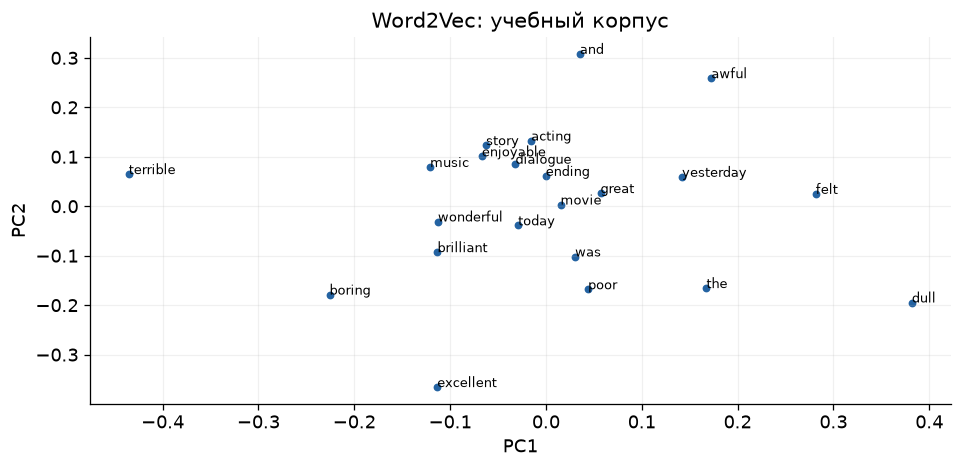

Word2Vec использует контексты слов, FastText — ещё и символьные n-граммы. Поэтому FastText строит вектор нового слова из знакомых частей. На маленьком корпусе рядом могут оказаться слова противоположной тональности.

In [2]:
from language_music import text_general, music_generation

text_general(OUT)

## Вариант 11. Музыкальные события и генерация продолжения

Корпус из сгенерированных учебных мотивов. Событие — MIDI pitch с фиксированной длительностью. Сравниваю пять конфигураций и десять продолжений с разными temperature и начальными нотами.

Корпус процедурный, авторские учебные мотивы. Pitch vocabulary: [48, 50, 52, 53, 55, 57, 60, 62, 64, 65, 67, 69, 72, 74, 76, 77, 79, 81, 84] число окон: 3600 1080 1080


,model,accuracy,macro_f1,validation_perplexity,seconds,parameters
0,RNN_32,0.88611,0.91570,1.31003,0.39796,2735
1,LSTM_32,0.88889,0.91883,1.31764,0.79453,7919
2,GRU_32,0.89352,0.92044,1.31732,0.69413,6191
3,LSTM_16,0.88796,0.86191,1.42149,0.57064,3135
4,LSTM_48,0.89352,0.92034,1.30766,1.04368,14751


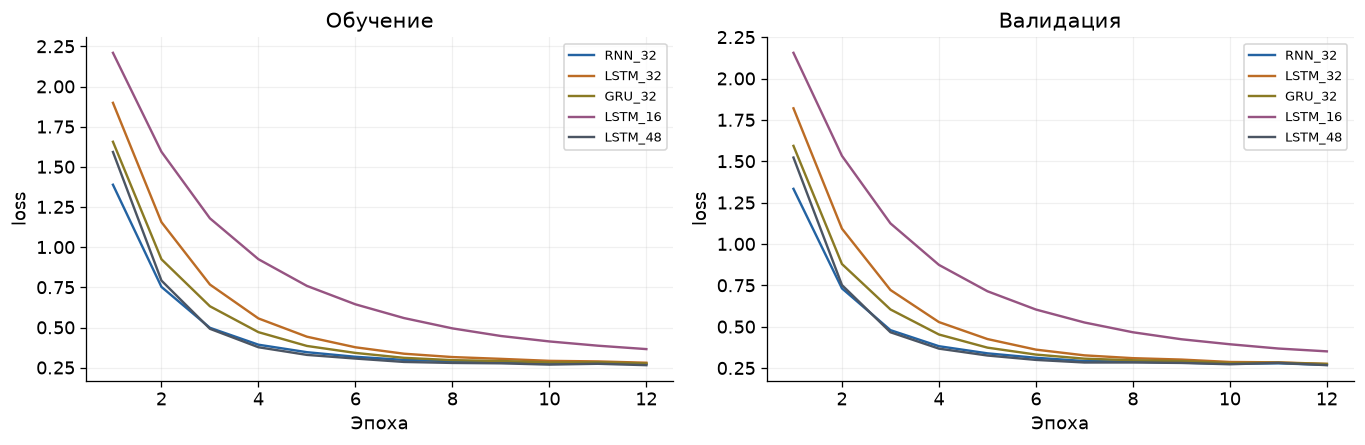

Выбрано по validation perplexity: LSTM_48 test: {'accuracy': 0.8953703703703704, 'macro_f1': 0.925385903587644}


,context,true_next,predicted_next,confidence,analysis
0,"[67, 64, 62, 60, 60, 62, 64, 67, 65, 64, 62, 60]",72,60,0.39237,После общего мотива выбрана другая ветвь продо...
1,"[64, 62, 60, 60, 62, 64, 67, 65, 64, 62, 60, 72]",79,76,0.45080,После общего мотива выбрана другая ветвь продо...
2,"[65, 64, 62, 60, 72, 79, 76, 81, 77, 79, 74, 72]",64,60,0.59213,После общего мотива выбрана другая ветвь продо...
3,"[79, 74, 72, 64, 67, 69, 67, 65, 64, 62, 60, 60]",62,64,0.39575,После общего мотива выбрана другая ветвь продо...
4,"[65, 64, 62, 60, 60, 62, 64, 67, 65, 64, 62, 60]",72,60,0.38932,После общего мотива выбрана другая ветвь продо...
5,"[64, 62, 60, 60, 62, 64, 67, 65, 64, 62, 60, 72]",79,76,0.45080,После общего мотива выбрана другая ветвь продо...
6,"[64, 62, 60, 60, 67, 64, 69, 65, 67, 62, 60, 60]",67,64,0.38655,После общего мотива выбрана другая ветвь продо...
7,"[65, 67, 62, 60, 60, 67, 64, 69, 65, 67, 62, 60]",64,60,0.37657,После общего мотива выбрана другая ветвь продо...
8,"[65, 64, 62, 60, 60, 64, 67, 72, 67, 64, 62, 60]",76,60,0.39975,После общего мотива выбрана другая ветвь продо...
9,"[65, 64, 62, 60, 60, 67, 64, 69, 65, 67, 62, 60]",64,60,0.37696,После общего мотива выбрана другая ветвь продо...


Markov baseline test accuracy: 0.475


,temperature,initial_melody,unique_pitches,repeated_4gram_fraction,consecutive_repeat_fraction
0,0.5,0,18,0.35484,0.05263
1,1.0,0,16,0.34409,0.05263
2,1.5,0,18,0.21505,0.04211
3,1.0,1,16,0.39785,0.04211
4,1.0,2,18,0.20430,0.01053
5,0.8,3,19,0.25806,0.01053
6,1.2,4,19,0.24731,0.02105
7,0.7,5,19,0.40860,0.01053
8,1.0,6,16,0.39785,0.04211
9,1.3,7,18,0.17204,0.05263


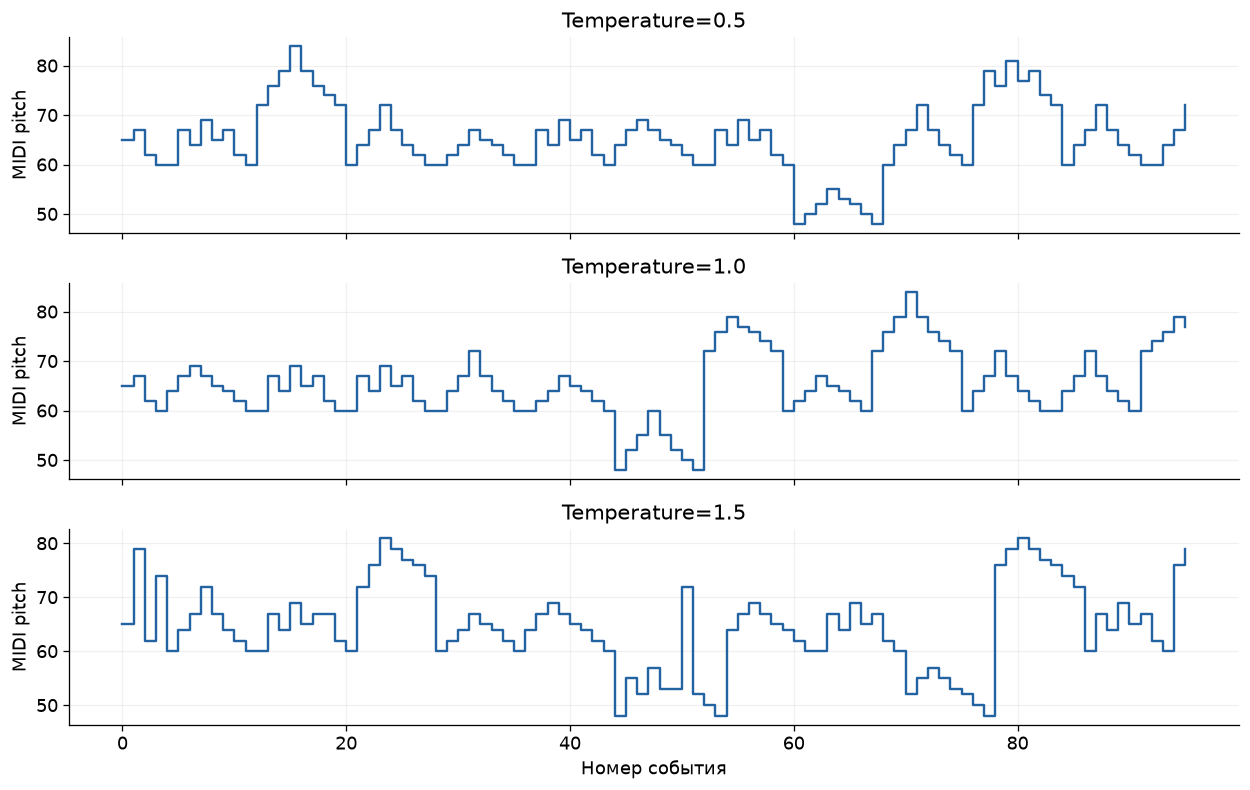

Длительность ноты — 1/8 при 120 BPM. При обучении использую истинную историю, при генерации — прогнозы модели. Низкая temperature усиливает повторы, высокая увеличивает случайность. Десять продолжений сохраняются в MIDI и WAV. Корпус состоит из учебных мотивов.

In [3]:
music_generation(OUT)

## Вывод по гипотезе

Проверяю, как модель запоминает мотивы и как temperature влияет на повторы и структуру мелодии.

In [4]:
note(
    "Модель обучена предсказывать следующую ноту по прошлым событиям. В таблицах представлены loss/perplexity, сравнение RNN/LSTM/GRU, Markov baseline, повторяемость 4-грамм и набор высот. Длительности, гармония и многоголосие в этом эксперименте фиксированы или отсутствуют. Для следующего шага можно добавить отдельные токены длительности и пауз, реальный MIDI-корпус и оценку на невиданных произведениях."
)

Модель обучена предсказывать следующую ноту по прошлым событиям. В таблицах представлены loss/perplexity, сравнение RNN/LSTM/GRU, Markov baseline, повторяемость 4-грамм и набор высот. Длительности, гармония и многоголосие в этом эксперименте фиксированы или отсутствуют. Для следующего шага можно добавить отдельные токены длительности и пауз, реальный MIDI-корпус и оценку на невиданных произведениях.

## Ответы на контрольные вопросы

1. PAD выравнивает длину batch, UNK представляет неизвестный токен. PAD исключается из состояния или loss через маску/packing.

2. Управляемый аддитивный путь cell state уменьшает риск многократного сокращения градиента по сравнению с обычной RNN.

3. Word2Vec хранит вектор слова; FastText также использует символьные n-граммы, что даёт представления редких и новых форм.

4. При teacher forcing модель получает истинную историю, а при генерации — собственную; ошибки истории создают exposure bias.

5. Двунаправленная модель недопустима, когда правая часть последовательности ещё неизвестна: causal-прогноз и онлайн-генерация.